# 00b — Review of the original project's backup (audit, 2026-11-01)

**What this is.** An older backup of the original project (`old files/solar_ds_capstone/`),
from about January 2026. **It is a step on the way, not the final project:** the project went
through several more iterations before the v6 submission. It is used as evidence of how the
original pipeline was built; wherever it disagrees with the submission, the submission prevails.

**How it was read.** Read-only. The working copy was listed, and the files that survive only in
its partial git history were recovered by decompressing the git objects; nothing from the backup
was executed. Coordinates found in it are private and are not shown.

**Why it matters.** It answers two questions the submission alone could not: which stage fed the
submitted feature selection, and where the original weather "forecast" came from.

**Documented in** `00_data_audit/original_backup_2026-11-01/README.md`, OP-45, findings F-26 to
F-28, test T-45, run journal RA-01 to RA-03.

## 1. What the backup holds

In [1]:
import json

import pandas as pd
from IPython.display import display

from solarpv.config.paths import AUDIT_DIR

HERE = AUDIT_DIR / "original_backup_2026-11-01"
inv = json.loads((HERE / "inventory_summary.json").read_text(encoding="utf-8"))
print("files:", inv["files"])
print("commits in the reflog:", inv["git"]["commits_in_reflog"])
display(pd.Series(inv["by_group"], name="files").to_frame())
pd.Series(inv["final_code_present"], name="present in the backup").to_frame()

files: {'working copy': 508, 'git history only': 400}
commits in the reflog: [{'date_utc': '2025-10-17', 'message': 'commit (initial): test'}, {'date_utc': '2025-10-17', 'message': 'commit: test'}, {'date_utc': '2026-01-20', 'message': 'commit: Initial commit'}, {'date_utc': '2026-01-20', 'message': 'commit: Initial commit'}]


,files
"EDA, ingest, preprocessing: superseded by stages 2-5",578
figures,171
modelling: intermediate,56
feature engineering: intermediate,39
raw export copies (same raw data as `Raw data/`),21
"configuration, IDE and other",17
feature selection: base stage that fed the submitted 05e,13
data tables: intermediate,9
weather source of the original NWP,3
feature selection: earlier version (Dec 2025),1


,present in the backup
xgb_sota.py,False
lstm_sota.py (PyTorch encoder-decoder),False
TFT (pytorch-forecasting),False
PatchTST,False
05c / 05e / 05f selection code,False


**What it shows.** 508 files in the working copy and
400 more that survive only in the git history. The reflog has
commits from 2025-10-17 to 2026-01-20. Most files are earlier versions of data ingest, EDA and
preprocessing, already rebuilt in stages 2–5.

**What is missing.** The final code is not there: not the tuned XGBoost (`xgb_sota.py`), not the
final PyTorch BiLSTM, not the TFT or PatchTST, and not the code of the 05c / 05e / 05f selection
steps. The reconstruction of those parts stays as planned (R-16).

## 2. The feature selection that fed the submission (F-26, F-27)

In [2]:
sel = json.loads((HERE / "selection_evidence.json").read_text(encoding="utf-8"))
params = {t: {k: (len(v) if isinstance(v, list) else v) for k, v in nb.items()
              if k in ("mi_threshold", "variance_threshold", "target_n_features", "cv_splits",
                       "core_features", "per_inverter_dc_forbidden",
                       "row_filter_by_split_or_date")}
          for t, nb in sel["base_notebooks"].items()}
early = sel["earlier_notebook_05_dec2025"]
params["notebook 05 (Dec 2025)"] = {"mi_threshold": early["mi_threshold"],
                                    "variance_threshold": early["variance_threshold"],
                                    "core_features": len(early["core_features"])}
display(pd.DataFrame(params))
pd.DataFrame(sel["fed_submitted_05e_D1"]).T

,direct,indirect,notebook 05 (Dec 2025)
per_inverter_dc_forbidden,False,True,NaN
core_features,12,12,17.000
variance_threshold,0.001,0.001,0.001
mi_threshold,0.02,0.02,0.010
target_n_features,42,42,NaN
cv_splits,5,5,NaN
row_filter_by_split_or_date,False,False,NaN


,n_base_output,n_05e_start,identical_sets,base_output_source
direct,42,42,True,selected_features_direct.json
indirect,42,42,True,feature names of the intermediate XGBoost xgb_...


**What it shows.** The configuration of the two base-selection notebooks of January 2026
(direct and indirect target), next to the earlier December notebook that survived in
`old files/`; and the comparison of their output with the submitted consensus files.

**What it means.**
- **These notebooks fed the submission.** Their
  42 features are exactly the starting
  features of the submitted D+1 consensus files, for both targets.
- **Their parameters differ from the December notebook:** MI threshold
  0.02 instead of 0.01, and a protected core of
  12 features instead of 17. Stage 7
  takes its base parameters from them.
- **No filter by split or date:** the selection saw the validation and test periods (F-26).

In [3]:
starts = pd.DataFrame(sel["submitted_05e_start_sets"]).T
starts["dropped_from_D1"] = starts["dropped_from_D1"].apply(", ".join)
starts

,n_start,subset_of_D1,dropped_from_D1
direct_D1,42,True,
direct_D2,36,True,"ambient_temp_lag_1d, mod_temp1_lag_1d, mod_tem..."
direct_D3,34,True,"ambient_temp_lag_1d, irradiance_lag_2d, mod_te..."
indirect_D1,42,True,
indirect_D2,36,True,"ambient_temp_lag_1d, irradiance_lag_1d, mod_te..."
indirect_D3,35,True,"ambient_temp_lag_1d, irradiance_lag_1d, mod_te..."


**What it shows.** The starting sets of the six submitted consensus files.

**What it means.** D+2 and D+3 start from the D+1 list minus the lags that are not known at that
horizon. The base selection ran once, on the D+1 table, and was not repeated per horizon.

,feature,mean_abs_shap,category
0,s01_inv2_DC_kW,0.764848,other
1,s01_inv1_DC_kW,0.180512,other
2,s01_inv2_rolling_mean_7d_same_tod,0.043854,rolling
3,doy_sin,0.001977,temporal
4,month_sin,0.000882,temporal


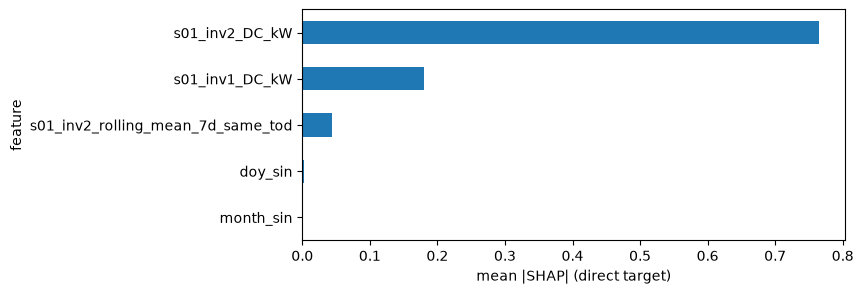

In [4]:
top = pd.read_csv(HERE / "selection_shap_direct_top.csv")
ax = top.iloc[::-1].plot.barh(x="feature", y="mean_abs_shap", legend=False, figsize=(7, 3))
ax.set_xlabel("mean |SHAP| (direct target)")
top

**What it shows.** The five most important features of the direct base selection.

**What it means.** The direct notebook forbade the site's total DC power but not the DC power of
each inverter, measured in the same hour that is being forecast: information that does not exist
at the time of the forecast. The two DC columns take 95% of the total
importance; the first is 17 times the third feature (F-27). The
submitted files removed them afterwards, but by then they had already decided the ranking and
the stopping point of the selection. The indirect notebook forbade them correctly.

**What stage 7 does instead.** Selection on the training period only, from a list of allowed
features (the corrected contract and the real GFS candidates), so a leaking column cannot
enter.

## 3. Where the original weather forecast came from (F-28)

In [5]:
wx = json.loads((HERE / "weather_source.json").read_text(encoding="utf-8"))
request = next(iter(wx["requests"].values()))[0]
print("endpoint:", request["endpoint"])
print("parameters:", request["parameters"])
print("variables:", request["hourly_variables"])
print("file:", wx["file"])

endpoint: https://archive-api.open-meteo.com/v1/archive
parameters: {'end_date': '2025-05-31', 'format': 'flatbuffers', 'models': 'gfs_seamless', 'start_date': '2021-09-01', 'timezone': 'UTC'}
variables: ['cloud_cover', 'diffuse_radiation', 'direct_radiation', 'shortwave_radiation', 'temperature_2m', 'wind_speed_10m']
file: {'rows': 32856, 'start_utc': '2021-09-01 00:00:00+00:00', 'end_utc': '2025-05-31 23:00:00+00:00', 'columns': ['fcst_temp_2m', 'fcst_cloud_cover', 'fcst_wind_speed', 'fcst_ghi', 'fcst_dni', 'fcst_dhi'], 'series': 'one hourly series for the whole period, no issue time'}


**What it shows.** The request stored in the cache of the original feature notebook:
`https://archive-api.open-meteo.com/v1/archive` with `models=gfs_seamless`, one request from
2021-09-01 to 2025-05-31.

**What it means.** One continuous series with no issue time. Every value is the one for the
target hour, so it could not have been known at the forecast time (midnight before the forecast
day). That is the leak; it was the reason the weather features were removed from the final
models.

,days,original,gfs_d1
train_and_val,1124.0,0.822,0.806
train,881.0,0.817,0.809
val,243.0,0.846,0.798


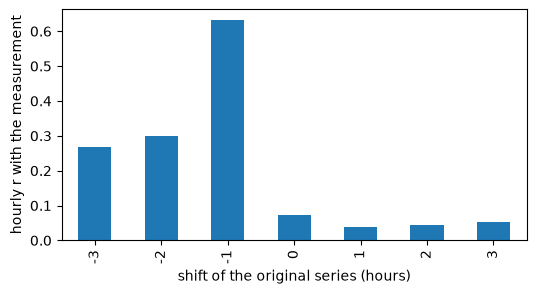

In [6]:
lag = pd.read_csv(HERE / "weather_lag_scan.csv")
ax = lag.plot.bar(x="shift_h", y="hourly_r", legend=False, figsize=(6, 3))
ax.set_xlabel("shift of the original series (hours)")
ax.set_ylabel("hourly r with the measurement")
pd.DataFrame(wx["skill"]["daily_r"]).T

**What it shows.** On train and validation hours, the correlation of the original series'
clear-sky index with the measured one, for shifts of −3 to +3 hours; and the daily correlation of
the original series and of the real D+1 GFS forecast of stage 6b.

**What it means.**
- **Not a perfect observation.** Its daily correlation with the measurement
  (0.822) is about that of a real day-ahead forecast
  (0.806). The problem was timing, not accuracy.
- **It needs a one-hour shift** to line up (hourly r 0.631), because the
  service labels each hour at its end. Joined 2–3 hours off the true clock, as in the original,
  the hourly r is 0.301 and
  0.268.
- **A likely reason the original weather features added little:** misaligned, they lost most of
  their hourly signal. The real GFS forecasts, aligned and available at issuance, lower the
  validation error by 0.9–1.7 points (D-12, `04c_nwp_gfs.ipynb`).

## 4. What this changes

- **Stage 7:** the base parameters come from the January notebooks that fed the submission; the
  selection runs on train only and from an allow-list (F-26, F-27).
- **The report:** the description of the original weather source is corrected (reanalysis →
  an archive series with no issue time, of day-ahead quality, misaligned in time; F-28).
- **Unchanged:** the final model code is not in the backup; stage 9 reconstructs it from the
  report and the surviving material, as planned.

**Reproduce.** The three scripts of `00_data_audit/original_backup_2026-11-01/`, then
`python scripts/make_original_backup_review_notebook.py`.